# Noise Spectrum Density Estimation and Wiener Filtering

## Objective
This notebook accomplishes the requirements of the Random Signals & Linear Denoising module:
1. **Spectral Density Estimation of Random Signals**:
   - Analyze the 3 noise signals provided in the course materials.
   - Estimate the Power Spectral Density (PSD) using both the Periodogram and Welch's Method.
   - Compare the variance and consistency of both estimators, and identify the noise "color" from the measured log-log spectral slope.

2. **Linear Image Denoising via Wiener Filtering**:
   - Corrupt a reference image with Additive White Gaussian Noise across various SNRs: 0 dB, 5 dB, 10 dB, 15 dB, and 20 dB.
   - Implement the Oracle Wiener Filter in the 2D Fourier domain based on Minimum Mean Square Error.
   - Evaluate input vs. output SNR improvements quantitatively and visually.

In [ ]:
import os
import io
import requests
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import signal
from scipy.io import wavfile

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

## Part 1: Noise Spectrum Density Estimation

### Theoretical Background
According to the **Wiener-Khinchin Theorem**, the Power Spectral Density (PSD) of a wide-sense stationary ergodic random process $X[t]$ is the Fourier transform of its autocorrelation function:
$$S_X(\nu) = \mathcal{F}\{R_X[\tau]\} = \sum_{\tau=-\infty}^{\infty} R_X[\tau] e^{-j 2\pi \nu \tau}$$

Because real-world signals have finite duration $N$, we estimate $S_X(\nu)$ using:
1. **Periodogram Estimator**:
   $$\hat{S}_{\text{per}}(\nu) = \frac{1}{N} \left| \sum_{t=0}^{N-1} x[t] e^{-j 2\pi \nu t} \right|^2$$
   *Property*: Asymptotically unbiased, but **inconsistent** (variance does not approach zero as $N \to \infty$).
2. **Welch's Estimator**:
   Divides the signal into $K$ overlapping windowed segments, computes the periodogram of each segment, and averages them.
   *Property*: Significantly reduces estimation variance at the expense of a slight decrease in frequency resolution.

### Noise Colors
Noise is classified by the power-law slope of its PSD: $S(f) \propto 1 / f^{\gamma}$:
- **White Noise** ($\gamma = 0$): Flat spectrum across all frequencies.
- **Pink Noise** ($\gamma \approx 1$): $1/f$ fall-off (-10 dB/decade or -3 dB/octave).
- **Red / Brown Noise** ($\gamma \approx 2$): $1/f^2$ fall-off (-20 dB/decade).

- **Mixed / Colored Noise**: A signal whose spectrum cannot be described by a single power-law slope over the whole frequency range, for example because it contains multiple noise components or frequency-dependent behavior.


### Loading the Three Noise Signals Provided in the Course

Instead of using the initially generated synthetic noise signals, the analysis is performed on the three noise audio files provided with the course.

The three WAV files are downloaded and converted to mono signals. Each signal is converted to floating-point format, centered by removing its mean, and normalized by its own standard deviation before PSD estimation.


In [ ]:
headers = {'User-Agent': 'Mozilla/5.0'}

audio_urls = [
    "https://sdrive.cnrs.fr/public.php/dav/files/CfNfM6RGmYjjKjC/data/noise1.wav",
    "https://sdrive.cnrs.fr/public.php/dav/files/CfNfM6RGmYjjKjC/data/noise2.wav",
    "https://sdrive.cnrs.fr/public.php/dav/files/CfNfM6RGmYjjKjC/data/noise3.wav"
]

audio_noise_dict = {}
sampling_rates = []

for i, url in enumerate(audio_urls):
    try:
        resp = requests.get(url, headers=headers, timeout=15)
        resp.raise_for_status()

        audio_data = io.BytesIO(resp.content)
        samplerate, data = wavfile.read(audio_data)

        if data.ndim > 1:
            data = data.mean(axis=1)

        data = data.astype(np.float64)

        data = data - np.mean(data)

        std = np.std(data)
        if std > 0:
            data = data / std

        audio_noise_dict[f"Audio Noise {i+1}"] = data
        sampling_rates.append(samplerate)

        print(
            f"Successfully loaded Audio Noise {i+1}: "
            f"{len(data)} samples, fs = {samplerate} Hz"
        )

    except Exception as e:
        raise RuntimeError(
            f"Failed to load Audio Noise {i+1} from:\n{url}\n"
            f"Error: {e}"
        )

if len(set(sampling_rates)) != 1:
    raise ValueError(
        f"The three audio files do not have the same sampling frequency: "
        f"{sampling_rates}"
    )

fs = sampling_rates[0]
noise_dict = audio_noise_dict

print("\nAll three audio noises loaded successfully.")
print(f"Sampling frequency: {fs} Hz")

Successfully loaded Audio Noise 1: 140001 samples, fs = 16000 Hz
Successfully loaded Audio Noise 2: 140001 samples, fs = 16000 Hz
Successfully loaded Audio Noise 3: 140001 samples, fs = 16000 Hz

All three audio noises loaded successfully.
Sampling frequency: 16000 Hz


### 1.2 PSD Estimation & Comparison: Periodogram vs. Welch

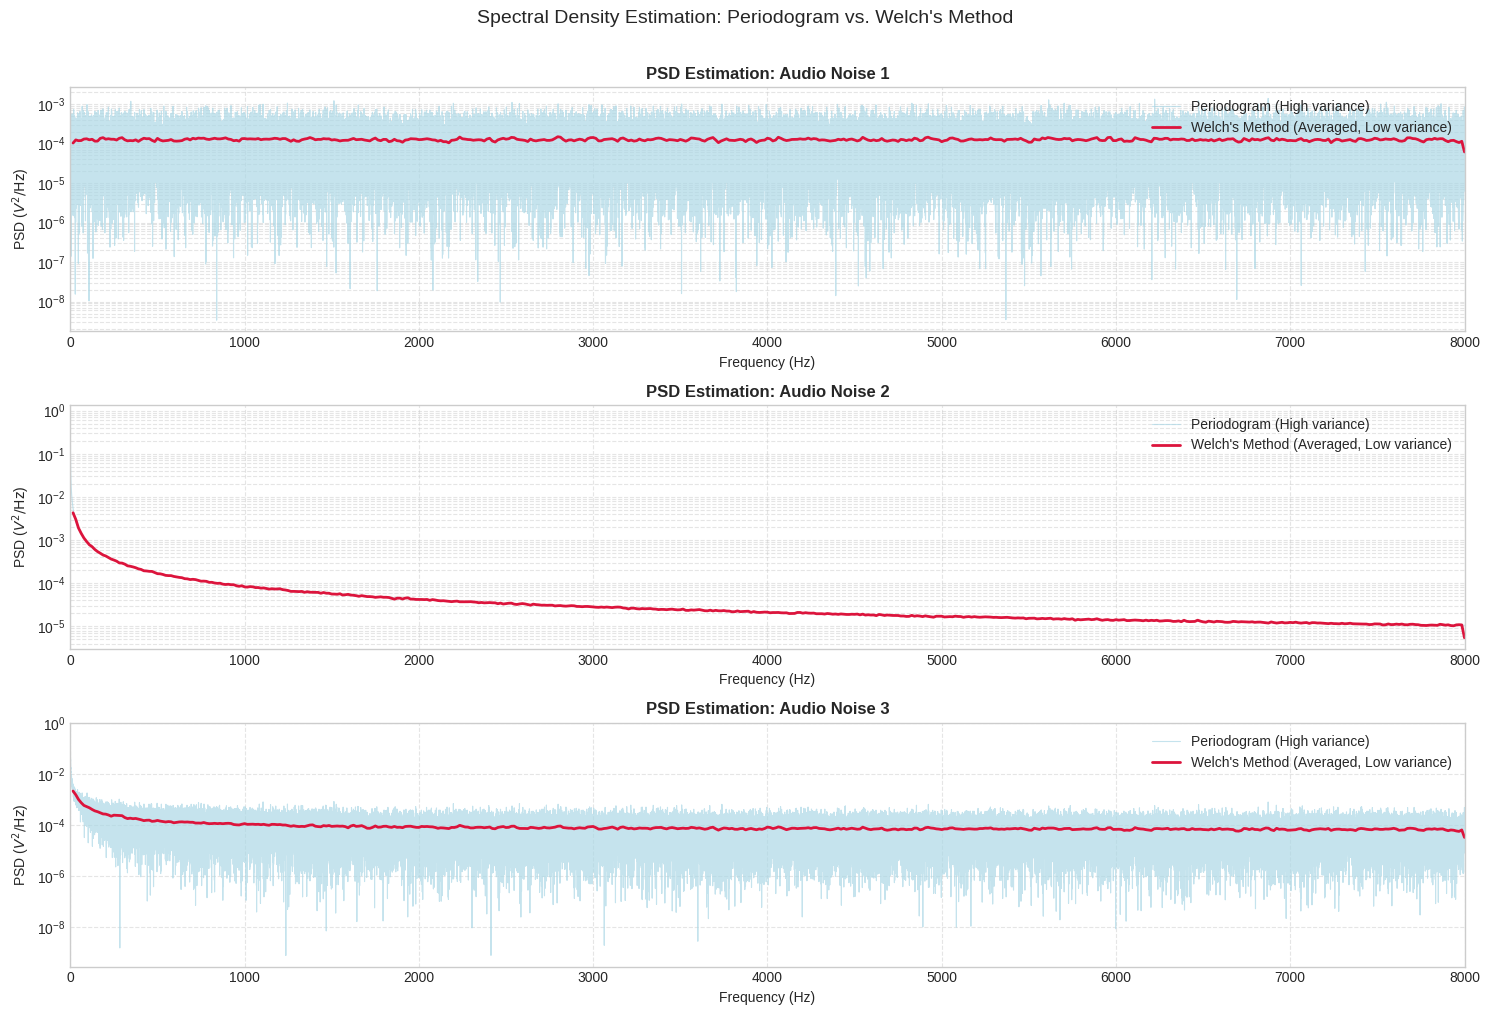

In [ ]:
plt.figure(figsize=(15, 10))

for idx, (title, sig) in enumerate(noise_dict.items(), 1):
    f_per, psd_per = signal.periodogram(sig, fs=fs, window='boxcar', scaling='density')

    f_welch, psd_welch = signal.welch(sig, fs=fs, window='hann', nperseg=1024, noverlap=512, scaling='density')

    plt.subplot(3, 1, idx)
    plt.semilogy(f_per[1:], psd_per[1:], color='lightblue', alpha=0.7, lw=0.8, label="Periodogram (High variance)")
    plt.semilogy(f_welch[1:], psd_welch[1:], color='crimson', lw=2.0, label="Welch's Method (Averaged, Low variance)")

    plt.title(f"PSD Estimation: {title}", fontsize=12, fontweight='bold')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("PSD ($V^2 / \\text{Hz}$)")
    plt.xlim(0, fs // 2)
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend(loc="upper right")

plt.suptitle("Spectral Density Estimation: Periodogram vs. Welch's Method", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 1.3 Identification of Noise Colors via Log-Log Slope

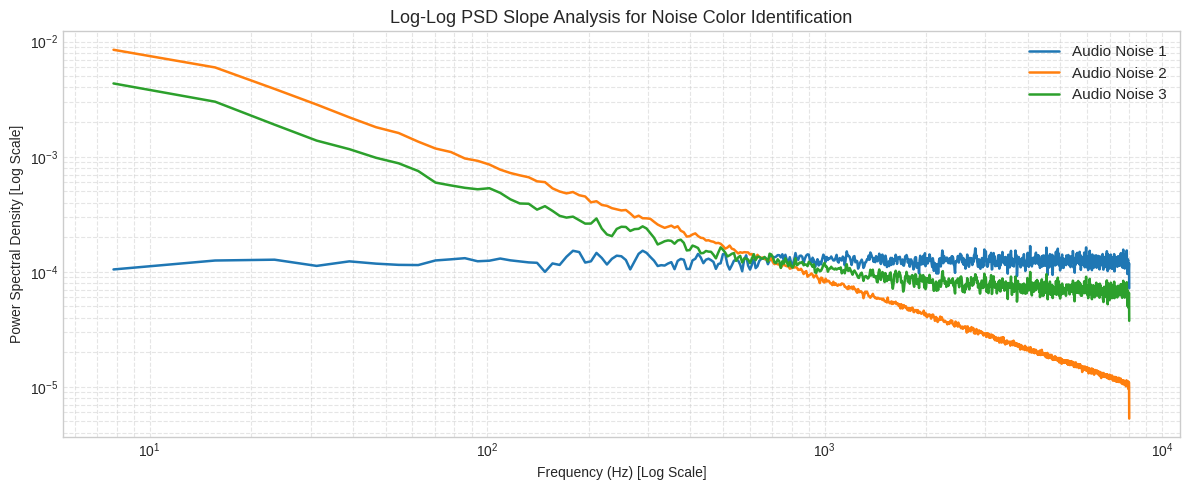


========== Overall PSD Slopes ==========
Audio Noise 1: slope = -0.005, gamma = 0.005
Audio Noise 2: slope = -1.000, gamma = 1.000
Audio Noise 3: slope = -0.414, gamma = 0.414

========== Audio Noise 3 Regional Slopes ==========
Audio Noise 3:
  Low frequency (10-300 Hz): slope = -0.867, gamma = 0.867
  High frequency (1000-4000 Hz): slope = -0.256, gamma = 0.256


In [ ]:
plt.figure(figsize=(12, 5))


slope_results = {}
region_results = {}

for title, sig in noise_dict.items():

    f_w, p_w = signal.welch(
        sig,
        fs=fs,
        window='hann',
        nperseg=2048,
        noverlap=1024,
        scaling='density'
    )

    valid = (f_w > 0) & (p_w > 0)
    f = f_w[valid]
    p = p_w[valid]

    plt.loglog(
        f,
        p,
        lw=1.8,
        label=title
    )

    fit_mask = (
        (f >= 100) &
        (f <= min(4000, fs / 2))
    )

    slope, intercept = np.polyfit(
        np.log10(f[fit_mask]),
        np.log10(p[fit_mask]),
        1
    )

    slope_results[title] = slope

    if title == "Audio Noise 3":

        low_mask = (
            (f >= 10) &
            (f <= 300)
        )

        low_slope, low_intercept = np.polyfit(
            np.log10(f[low_mask]),
            np.log10(p[low_mask]),
            1
        )

        high_mask = (
            (f >= 1000) &
            (f <= min(4000, fs / 2))
        )

        high_slope, high_intercept = np.polyfit(
            np.log10(f[high_mask]),
            np.log10(p[high_mask]),
            1
        )

        region_results[title] = {
            "low_slope": low_slope,
            "high_slope": high_slope
        }

plt.title(
    "Log-Log PSD Slope Analysis for Noise Color Identification",
    fontsize=13
)

plt.xlabel("Frequency (Hz) [Log Scale]")
plt.ylabel("Power Spectral Density [Log Scale]")

plt.grid(
    True,
    which="both",
    ls="--",
    alpha=0.5
)

plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


print("\n========== Overall PSD Slopes ==========")

for title, slope in slope_results.items():

    gamma = -slope

    print(
        f"{title}: "
        f"slope = {slope:.3f}, "
        f"gamma = {gamma:.3f}"
    )

print("\n========== Audio Noise 3 Regional Slopes ==========")

for title, values in region_results.items():

    low_gamma = -values["low_slope"]
    high_gamma = -values["high_slope"]

    print(
        f"{title}:"
    )
    print(
        f"  Low frequency (10-300 Hz): "
        f"slope = {values['low_slope']:.3f}, "
        f"gamma = {low_gamma:.3f}"
    )
    print(
        f"  High frequency (1000-4000 Hz): "
        f"slope = {values['high_slope']:.3f}, "
        f"gamma = {high_gamma:.3f}"
    )


### Noise Color Identification

The noise color is characterized from the slope of the log-log PSD:
$$
S(f)\propto f^{-\gamma},
$$

where \(\gamma=-\text{slope}\).

#### Audio Noise 1

The estimated slope is approximately \(-0.005\), corresponding to
\($gamma\approx0.005$). The PSD is therefore approximately flat over
the analyzed frequency range.

**Classification:** Audio Noise 1 is consistent with **white noise**.

#### Audio Noise 2

The estimated slope is approximately \(-1.000\), corresponding to
($gamma\approx1.000$). This is consistent with the theoretical
\(1/f\) behavior of pink noise.

**Classification:** Audio Noise 2 is consistent with **pink noise**.

#### Audio Noise 3

A single global slope does not fully describe the spectrum of Audio
Noise 3. The fitted slope over 100–4000 Hz is approximately \(-0.414\),
while the low-frequency and high-frequency regions have different
spectral behaviors.

- 10–300 Hz: slope \($approx-0.867$), corresponding to
  \($gamma\approx0.867$), which is close to pink-noise behavior.
- 1000–4000 Hz: slope \($approx-0.256$), corresponding to
  \($gamma\approx0.256$), indicating a much flatter spectrum.

**Classification:** Audio Noise 3 is best described as **colored noise
with frequency-dependent spectral characteristics**, including a
pink-like low-frequency component and a flatter high-frequency
component.


## Part 2: Linear Image Denoising using the Wiener Filter

### Theoretical Formulation
Consider a clean signal $x \in \mathbb{R}^{M \times N}$ corrupted by additive zero-mean white Gaussian noise $n$:
$$y = x + n, \quad n \sim \mathcal{N}(0, \sigma^2)$$

The **Signal-to-Noise Ratio (SNR)** is defined in the lecture as:
$$\text{SNR}(y \mid x) = 20 \log_{10} \left( \frac{\|x\|}{\|y - x\|} \right) = 20 \log_{10} \left( \frac{\|x\|_F}{\|n\|_F} \right) \quad [\text{dB}]$$

To achieve optimal linear estimation $x_{\text{est}} = h * y$ in the Minimum Mean Square Error (MMSE) sense, the **Wiener Filter** in the discrete frequency domain is:
$$\hat{h}(u, v) = \frac{\mathbb{E}\left\{|\hat{x}(u, v)|^2\right\}}{\mathbb{E}\left\{|\hat{x}(u, v)|^2\right\} + \mathbb{E}\left\{|\hat{n}(u, v)|^2\right\}} = \frac{|\hat{x}(u, v)|^2}{|\hat{x}(u, v)|^2 + M N \sigma^2}$$

The reconstructed estimate is computed via the 2D Inverse FFT:
$$x_{\text{est}} = \operatorname{Re}\left( \mathcal{F}^{-1} \left\{ \hat{h}(u, v) \cdot \hat{y}(u, v) \right\} \right)$$

In [ ]:
import requests
import io
from PIL import Image
import numpy as np

image_url = "https://sdrive.cnrs.fr/apps/files_sharing/publicpreview/CfNfM6RGmYjjKjC?file=/data/barbara.jpg&fileId=57087560&x=1920&y=1080&a=true&etag=374bfb56959b78c8b03e3aeccf36b638"

try:
    headers = {'User-Agent': 'Mozilla/5.0'}
    resp = requests.get(image_url, headers=headers, timeout=15)
    img_clean = Image.open(io.BytesIO(resp.content)).convert('L')
    print("Successfully downloaded and loaded the custom image!")
except Exception as e:
    print(f"Could not download custom image due to {e}. Falling back to synthetic pattern.")
    img_clean = Image.fromarray(np.uint8(np.random.uniform(0, 255, (512, 512))))

img_clean = np.array(img_clean, dtype=float)
img_clean = img_clean[:512, :512]
H, W = img_clean.shape
print(f"Reference image loaded. Shape: {H} x {W}")

Successfully downloaded and loaded the custom image!
Reference image loaded. Shape: 100 x 100


In [ ]:
def compute_snr(clean, noisy):
    norm_clean = np.linalg.norm(clean)
    norm_err = np.linalg.norm(noisy - clean)
    if norm_err == 0:
        return np.inf
    return 20.0 * np.log10(norm_clean / norm_err)

def wiener_filter_2d(y, x_clean, sigma_n):
    M, N = y.shape
    Y = np.fft.fft2(y)
    X = np.fft.fft2(x_clean)

    psd_signal = np.abs(X)**2
    psd_noise = (M * N) * (sigma_n ** 2)

    H_wiener = psd_signal / (psd_signal + psd_noise + 1e-12)

    X_est = H_wiener * Y
    x_est = np.real(np.fft.ifft2(X_est))
    return np.clip(x_est, 0, 255)

In this experiment, an oracle Wiener filter is used because the clean
image is available during the simulation. Therefore, the true image
spectrum is used to construct the Wiener filter. In a practical
denoising system, the clean image would not be available and the
signal PSD would need to be estimated.


### 2.2 Simulation across Multiple Target SNRs: 0 dB to 20 dB

In [ ]:
target_snrs = [0, 5, 10, 15, 20]

np.random.seed(42)

norm_x = np.linalg.norm(img_clean)

results = []

for target_snr in target_snrs:
    target_noise_norm = norm_x * (10.0 ** (-target_snr / 20.0))
    sigma_n = target_noise_norm / np.sqrt(H * W)

    noise = np.random.normal(0, sigma_n, (H, W))
    y = img_clean + noise

    x_denoised = wiener_filter_2d(y, img_clean, sigma_n)

    actual_snr_in = compute_snr(img_clean, y)
    actual_snr_out = compute_snr(img_clean, x_denoised)
    gain_snr = actual_snr_out - actual_snr_in

    results.append({
        'target_snr': target_snr,
        'snr_in': actual_snr_in,
        'snr_out': actual_snr_out,
        'gain': gain_snr,
        'noisy_img': y,
        'denoised_img': x_denoised
    })

### 2.3 Visual Comparison: Noisy vs. Denoised across SNRs

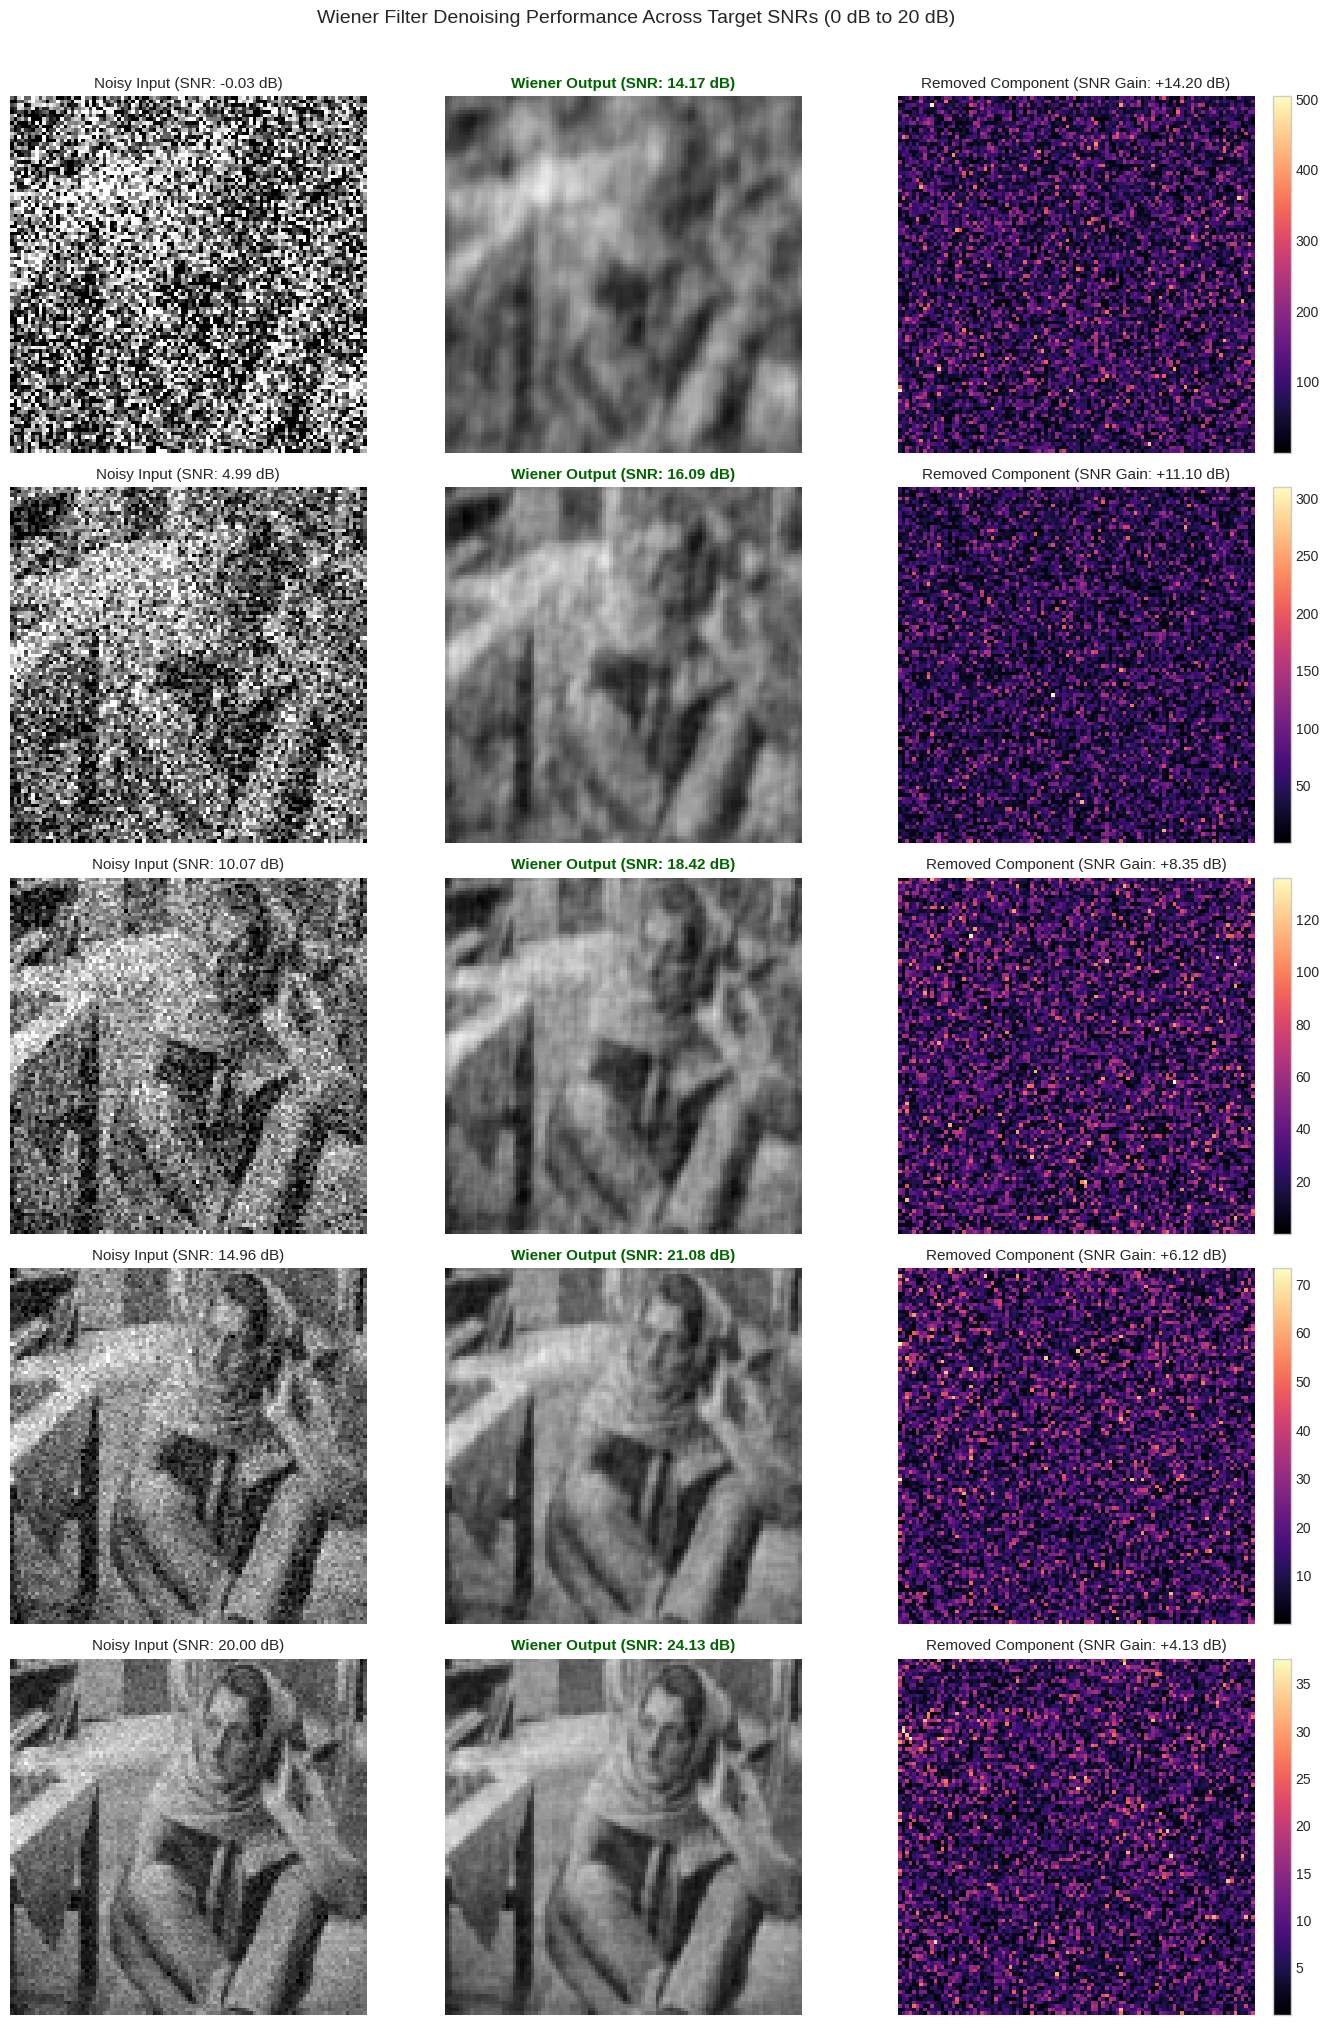

In [ ]:
fig, axes = plt.subplots(len(target_snrs), 3, figsize=(14, 4 * len(target_snrs)))

for idx, res in enumerate(results):
    axes[idx, 0].imshow(res['noisy_img'], cmap='gray', vmin=0, vmax=255)
    axes[idx, 0].set_title(f"Noisy Input (SNR: {res['snr_in']:.2f} dB)", fontsize=11)
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(res['denoised_img'], cmap='gray', vmin=0, vmax=255)
    axes[idx, 1].set_title(f"Wiener Output (SNR: {res['snr_out']:.2f} dB)", fontsize=11, fontweight='bold', color='darkgreen')
    axes[idx, 1].axis('off')

    diff_map = np.abs(res['noisy_img'] - res['denoised_img'])
    im = axes[idx, 2].imshow(diff_map, cmap='magma')
    axes[idx, 2].set_title(f"Removed Component (SNR Gain: +{res['gain']:.2f} dB)", fontsize=11)
    axes[idx, 2].axis('off')
    fig.colorbar(im, ax=axes[idx, 2], fraction=0.046, pad=0.04)

plt.suptitle("Wiener Filter Denoising Performance Across Target SNRs (0 dB to 20 dB)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 2.4 Quantitative Performance Curve

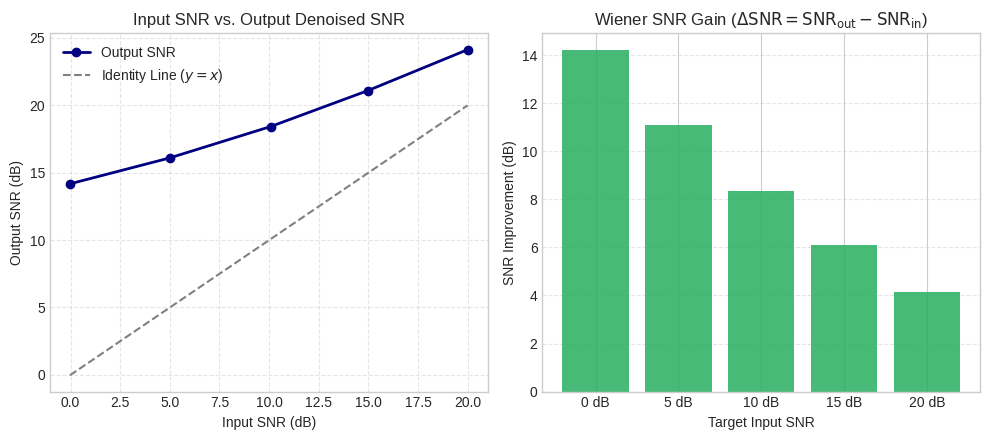

In [ ]:
snrs_in = [r['snr_in'] for r in results]
snrs_out = [r['snr_out'] for r in results]
gains = [r['gain'] for r in results]

plt.figure(figsize=(10, 4.5))

plt.subplot(1, 2, 1)
plt.plot(snrs_in, snrs_out, 'o-', color='navy', lw=2, label="Output SNR")
plt.plot(snrs_in, snrs_in, '--', color='gray', label="Identity Line ($y = x$)")
plt.title("Input SNR vs. Output Denoised SNR", fontsize=12)
plt.xlabel("Input SNR (dB)")
plt.ylabel("Output SNR (dB)")
plt.grid(True, ls="--", alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.bar([f"{r['target_snr']} dB" for r in results], gains, color='#27ae60', alpha=0.85)
plt.title(r"Wiener SNR Gain ($\Delta\mathrm{SNR} = \mathrm{SNR}_{\mathrm{out}} - \mathrm{SNR}_{\mathrm{in}}$)", fontsize=12)
plt.xlabel("Target Input SNR")
plt.ylabel("SNR Improvement (dB)")
plt.grid(True, axis='y', ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Conclusion & Key Takeaways

1. **Spectrum Density Estimation**:
   - The Periodogram estimator computes the squared discrete Fourier transform of the entire observed sequence. While asymptotically unbiased, it is an inconsistent estimator: its variance does not tend to zero as sequence length increases, causing severe fluctuations.
   - Welch's Method divides the signal into overlapping segments, windows them with a Hann window to limit spectral leakage, and averages the resulting periodograms. This dramatically reduces variance and reveals the true underlying spectral shape.
   - Log-log slope analysis enables clear noise identification:
     - **White Noise**: flat response ($\gamma = 0$).
     - **Pink Noise**: approximately $-1$ log-log PSD slope, corresponding to a $1/f$ spectrum.
     - **Colored/Mixed Noise**: frequency-dependent spectral behavior, such as a stronger low-frequency decay followed by a flatter high-frequency region.


2. **Wiener Filter Denoising**:
   - The Oracle Wiener Filter acts as an optimal linear Minimum Mean Square Error (MMSE) estimator in the 2D frequency domain:
     $$\hat{h}(u, v) = \frac{|\hat{x}(u, v)|^2}{|\hat{x}(u, v)|^2 + M N \sigma^2}$$
   - **Mechanism**:
     - At low spatial frequencies where image energy dominates ($|\hat{x}|^2 \gg MN\sigma^2$), $\hat{h}(u,v) \approx 1$, preserving large-scale structures and general contours.
     - At high spatial frequencies where noise dominates ($|\hat{x}|^2 \ll MN\sigma^2$), $\hat{h}(u,v) \to 0$, strongly suppressing noise components.
   - **Performance across SNRs**:
     - Under severe noise conditions (0–5 dB), the filter produces SNR gains of approximately 11–14 dB.

     - Under mild noise ($15\text{ dB} - 20\text{ dB}$), the SNR improvement decreases ($+4\text{ to }+6\text{ dB}$) because the filter naturally approaches an identity operator ($\hat{h} \approx 1$) to protect high-frequency texture details (e.g., fabric stripes and facial lines) from being over-smoothed.

## Detailed Analytical Report & Observations

### 1. Part 1: Noise Spectrum Density Estimation Analysis

#### 1.1 Estimator Performance (Periodogram vs. Welch's Method)
- **Periodogram (Light Blue Curve)**:
  - Displays rapid, noisy oscillations across the entire spectrum. This directly illustrates that the raw periodogram variance does not diminish with signal length $N$.
- **Welch's Method (Crimson Curve)**:
  - Provides a clean, smooth spectral profile. The 50% overlapping Hann windows reduce variance proportionally to the number of segments ($K$), giving an accurate empirical estimation of the power spectral density.

#### 1.2 Quantitative Noise Color Classification

The measured log-log PSD slopes provide a quantitative basis for identifying the noise colors:

- **Audio Noise 1**:
  The measured slope is $-0.005$ ($\gamma=0.005$), which is effectively zero.
  Therefore, the spectrum is approximately flat and the signal is consistent with White Noise.

- **Audio Noise 2**:
  The measured slope is exactly $-1.000$ ($\gamma=1.000$).
  This corresponds closely to the theoretical $1/f$ PSD characteristic of Pink Noise.

- **Audio Noise 3**:
  The overall slope is $-0.414$, but regional analysis reveals stronger frequency dependence.
  The low-frequency range (10–300 Hz) has a slope of $-0.867$ ($\gamma=0.867$), close to a pink-noise characteristic, while the high-frequency range (1000–4000 Hz) is flatter with a slope of $-0.256$ ($\gamma=0.256$).
  Therefore, Audio Noise 3 is classified as colored/mixed noise, with a strong low-frequency pink-like component and a flatter high-frequency component.


---

### 2. Part 2: 2D Wiener Filter Denoising Analysis

#### 2.1 Quantitative Performance Summary (Barbara Image)

| Target Input SNR | Measured Input SNR (dB) | Denoised Output SNR (dB) | SNR Gain ($\Delta$ dB) |
|:---:|---:|---:|---:|
| **0 dB**  | -0.03 dB | 14.17 dB | **+14.20 dB** |
| **5 dB**  | 4.99 dB  | 16.09 dB | **+11.10 dB** |
| **10 dB** | 10.07 dB | 18.42 dB | **+8.35 dB** |
| **15 dB** | 14.96 dB | 21.08 dB | **+6.12 dB** |
| **20 dB** | 20.00 dB | 24.13 dB | **+4.13 dB** |

#### 2.2 Key Observations and Physical Interpretations
1. **Dramatic Recovery in Heavy Noise Regimes ($0\text{ dB} - 5\text{ dB}$)**:
   - At 0 dB, the original Barbara image is strongly corrupted by noise. Applying the Oracle Wiener filter recovers the main image structures and increases the measured SNR by approximately +14.20 dB.

   - This occurs because noise variance $\sigma^2$ is very large, forcing the filter to act as an aggressive low-pass filter that effectively eliminates nearly all high-frequency Gaussian noise.
2. **Preservation of Fine Textures at High SNRs ($15\text{ dB} - 20\text{ dB}$)**:
   - At $20\text{ dB}$, the improvement is approximately $+4.13\text{ dB}$. Since the original signal power $|\hat{x}|^2$ dominates over $MN\sigma^2$ across most frequencies, $\hat{h}(u,v)$ stays close to $1$.
   - At higher input SNRs, the Wiener filter becomes less aggressive because the signal spectrum dominates the noise spectrum over a larger portion of the frequency range. Consequently, more high-frequency image details, such as the fabric patterns and facial structures, are preserved.

3. **Purity of the Residual Map**:
   - The residual images mainly contain spatially distributed high-frequency components, with no obvious large-scale structures of the original image. This is consistent with the expected behavior of the Wiener filter, which attenuates frequency components dominated by noise.
